# Визуализация данных ресторанов

Лабораторная работа 1. Ноутбук читает CSV, очищает таблицу и строит рисунки в Seaborn и Plotly. Подписи и комментарии на русском. Рисунки сохраняются в каталог `media` рядом с этим ноутбуком, данные читаются из `dataset.csv` в том же каталоге. Файл отчёта `.docx` здесь не собирается.

Цель и задачи ниже взяты из методических указаний без пересказа. Пример шаблона отчёта про продажи игр задаёт форму отчёта, а не тему: считаем выданный файл ресторанов.


## Цель работы

Необходимо написать программу для визуализации динамических (сериальных) данных. Возможен экспорт-импорт в подходящие для чтения приложением в текстовом формате (CSV, XML), возможно чтение данных в реальном времени с сетевых ресурсов.

## Задачи

1. Изучить данные и описать их предметную область.
2. Сформулировать гипотезу с использованием методов визуализации для исследования или принятия решения.
3. Выбрать средства для визуализации данных и подготовить данные.
4. Визуализировать данные с помощью библиотеки Seaborn.
5. Визуализировать данные с помощью библиотеки Plotly.

В выданном файле один снимок CSV и нет столбца времени, поэтому программа читает CSV и сравнивает рестораны между собой. Линейный график по годам из примера с видеоиграми здесь не строится. XML и чтение потока в этом файле тоже не из чего собрать.


## Предметная область и связь с методичкой

Строка таблицы — одно заведение. Столбцы исходного файла:

| Столбец | Смысл |
| --- | --- |
| Restaurant | идентификатор вида `Rest_N`; в графиках не используется |
| Cuisine | тип кухни, шесть значений: Chinese, French, Indian, Italian, Japanese, Mexican |
| Avg_Check | средний чек |
| Orders | число заказов |
| Rating | рейтинг; по наблюдаемой шкале это баллы от 1 до 5 |
| Reviews | число отзывов |

Методичка показывает приёмы на двух чужих наборах: продажи и оценки видеоигр, затем отток клиентов связи. На рестораны переносится приём, а не тема.

| Приём в методичке | На чём он показан | Что строим на ресторанах |
| --- | --- | --- |
| `pairplot` | продажи и оценки игр | чек, заказы, рейтинг, отзывы; цвет — кухня |
| `distplot` оценок критиков | гистограмма и плотность | гистограмма рейтинга. `distplot` устарел, вместо него `histplot` |
| `jointplot` | оценка критиков и оценка пользователей | средний чек и рейтинг |
| `boxplot` Seaborn | оценки по платформам | рейтинг по кухням |
| тепловая карта | продажи «платформа × жанр»; во второй части — корреляции | корреляции четырёх чисел. Второй категориальный признак, кроме кухни, в файле отсутствует |
| линия по `Year_of_Release` | динамика продаж | не строим: даты нет |
| столбцы Plotly | доля платформ по числу игр и по выручке | доля заведений и доля оборота по кухням |
| ящик Plotly | оценки критиков по жанрам | средний чек по кухням |
| интерактивное рассеяние | в методичке связь двух оценок показана `jointplot`; в Plotly тот же вопрос удобно смотреть точками с легендой | средний чек и рейтинг, цвет — кухня |

Оборот в файле отдельно не записан. Для столбцов долей он считается как произведение среднего чека и числа заказов — аналог `Global_Sales` из примера, с явной оговоркой, что это производная величина.

t-SNE из второй половины методички не строим: в списке задач лабораторной его нет, а для гипотезы ниже хватает ящиков, корреляций и рассеяния.


In [1]:
%matplotlib inline

from pathlib import Path
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio

# В методичке фигуру показывают через plotly.offline.iplot.
# В текущем Plotly тот же объект Figure открывается методом show().
pio.renderers.default = "plotly_mimetype"

DATA_PATH = Path(
    "dataset.csv"
)
MEDIA_DIR = Path(
    "media"
)
MEDIA_DIR.mkdir(parents=True, exist_ok=True)

# Пороги решения по гипотезе. Заданы до графиков.
# 0.2 — слабая, но уже заметная на картинке линейная связь.
# 0.2 балла рейтинга, 10 заказов и 2 единицы чека — сдвиг медианы,
# который имел бы смысл при выборе кухни для расширения.
CORR_LIMIT = 0.2
RATING_MEDIAN_SPAN = 0.2
ORDERS_MEDIAN_SPAN = 10
CHECK_MEDIAN_SPAN = 2

# Пороги отбраковки. Для заказов, рейтинга и отзывов они стоят
# внутри пустого разрыва между основной массой и оторванным кластером.
# Для среднего чека разрыва нет, порог считается по усам Тьюки в ячейке очистки.
ORDERS_MAX = 300
RATING_MIN = 1
RATING_MAX = 5
REVIEWS_MAX = 100

CUISINE_RU = {
    "Chinese": "Китайская",
    "French": "Французская",
    "Indian": "Индийская",
    "Italian": "Итальянская",
    "Japanese": "Японская",
    "Mexican": "Мексиканская",
}
CUISINE_ORDER = [
    "Индийская",
    "Итальянская",
    "Китайская",
    "Мексиканская",
    "Французская",
    "Японская",
]
RU = {
    "Avg_Check": "Средний чек",
    "Orders": "Число заказов",
    "Rating": "Рейтинг",
    "Reviews": "Число отзывов",
}
VARIABLES = list(RU.items())
SINGLE_COLOR = "#4C78A8"

sns.set_theme(
    style="whitegrid",
    font="DejaVu Sans",
    rc={
        "axes.unicode_minus": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "figure.titlesize": 14,
    },
)
PALETTE = dict(
    zip(CUISINE_ORDER, sns.color_palette("Set2", n_colors=len(CUISINE_ORDER)).as_hex())
)


def save_mpl(fig, filename):
    # PNG для последующей вставки в отчёт. bbox_inches не обрезает подписи.
    path = MEDIA_DIR / filename
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    print(path)
    return path


def apply_layout(fig, title, x_title, y_title, legend_title=None, height=560):
    fig.update_layout(
        template="plotly_white",
        title=dict(text=title, x=0.5, xanchor="center"),
        xaxis_title=x_title,
        yaxis_title=y_title,
        font=dict(family="DejaVu Sans", size=13, color="#1f1f1f"),
        width=980,
        height=height,
        margin=dict(l=70, r=40, t=80, b=80),
    )
    if legend_title:
        fig.update_layout(legend_title_text=legend_title)


def save_plotly(fig, stem):
    # HTML сохраняет наведение и отключение рядов, PNG — статичный кадр того же рисунка.
    png = MEDIA_DIR / f"{stem}.png"
    html = MEDIA_DIR / f"{stem}.html"
    fig.write_image(png, scale=2)
    fig.write_html(html, include_plotlyjs=True, full_html=True)
    print(png)
    print(html)
    fig.show()


def max_abs_offdiag(corr):
    values = corr.to_numpy(dtype=float)
    mask = ~np.eye(values.shape[0], dtype=bool)
    return float(np.nanmax(np.abs(values[mask])))


## 1. Изучение данных и их предметной области

Для того чтобы описать предметную область и решить, можно ли строить графики, сначала проверяем, что файл прочитался, какие у столбцов типы, где пропуски и насколько сильно разъезжаются числа.

Данные загружаются методом `read_csv`. Метод `info` показывает число строк, типы и число непустых значений. `describe` даёт среднее, стандартное отклонение, минимум, квартили и максимум. `isna` считает пропуски по столбцам. Имена и кухни дополнительно проверяются на пустые строки и на значения вне списка шести кухонь.


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(DATA_PATH)

df = pd.read_csv(DATA_PATH)
expected = ["Restaurant", "Cuisine", "Avg_Check", "Orders", "Rating", "Reviews"]
if list(df.columns) != expected:
    raise ValueError(f"Ожидались столбцы {expected}, в файле {list(df.columns)}")

# Пустая строка после чтения — тоже пропуск, не отдельная категория.
for column in ["Restaurant", "Cuisine"]:
    df[column] = df[column].astype("string").str.strip()
    df.loc[df[column].isna() | (df[column] == ""), column] = pd.NA

print(f"Файл: {DATA_PATH.name}")
print(f"Размер: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.info()
display(df.head(8))

missing = pd.DataFrame({
    "Пропуски": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2),
})
missing.index = missing.index.map({
    "Restaurant": "Ресторан",
    "Cuisine": "Кухня",
    "Avg_Check": "Средний чек",
    "Orders": "Число заказов",
    "Rating": "Рейтинг",
    "Reviews": "Число отзывов",
})
display(missing)
display(df.describe().T.round(3))

print("Кухни, включая пропуски:")
display(df["Cuisine"].value_counts(dropna=False))

unknown = set(df["Cuisine"].dropna().unique()) - set(CUISINE_RU)
if unknown:
    raise ValueError(f"В файле есть кухни вне ожидаемого списка: {sorted(unknown)}")

named = df["Restaurant"].dropna()
print(f"Непустых имён: {len(named)}, уникальных: {named.nunique()}")
numbers = named.str.extract(r"^Rest_(\d+)$", expand=False)
parsed = numbers.notna()
same_index = (
    numbers[parsed].astype(int).to_numpy()
    == named.index[parsed.to_numpy()].to_numpy()
)
print(f"Имена вида Rest_N: {int(parsed.sum())} из {len(named)}")
print(f"Номер в имени совпадает с индексом строки: {bool(same_index.all())}")

for column in ["Orders", "Reviews"]:
    fractional = df.loc[df[column].notna(), column] % 1 != 0
    if bool(fractional.any()):
        raise ValueError(f"В столбце {column} есть дробные значения")
print("Заказы и отзывы целочисленные там, где они заполнены.")
print(f"Максимум заказов в файле: {df['Orders'].max():.0f}")
print(f"Строк с Orders = 3553: {int((df['Orders'] == 3553).sum())}")


Файл: dataset.csv
Размер: 16683 строк, 6 столбцов
<class 'pandas.DataFrame'>
RangeIndex: 16683 entries, 0 to 16682
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Restaurant  14985 non-null  string 
 1   Cuisine     14997 non-null  string 
 2   Avg_Check   15011 non-null  float64
 3   Orders      15002 non-null  float64
 4   Rating      15014 non-null  float64
 5   Reviews     14990 non-null  float64
dtypes: float64(4), string(2)
memory usage: 782.1 KB


,Restaurant,Cuisine,Avg_Check,Orders,Rating,Reviews
0,Rest_0,Chinese,21.77,201.0,2.8,46.0
1,Rest_1,Japanese,20.01,231.0,3.4,41.0
2,Rest_2,Mexican,NaN,211.0,NaN,NaN
3,Rest_3,Japanese,8.67,222.0,5.0,47.0
4,Rest_4,French,8.42,193.0,4.3,37.0
5,Rest_5,Chinese,11.50,207.0,3.9,NaN
6,<NA>,Italian,25.01,184.0,5.0,45.0
7,Rest_7,Chinese,13.81,197.0,2.7,49.0


,Пропуски,"Доля, %"
Ресторан,1698,10.18
Кухня,1686,10.11
Средний чек,1672,10.02
Число заказов,1681,10.08
Рейтинг,1669,10.00
Число отзывов,1693,10.15


,count,mean,std,min,25%,50%,75%,max
Avg_Check,15011.0,24.371,21.556,1.89,14.585,20.32,28.74,586.08
Orders,15002.0,235.830,360.419,150.00,191.000,200.00,210.00,4503.00
Rating,15014.0,4.299,3.341,1.10,3.500,4.00,4.50,45.00
Reviews,14990.0,58.401,86.272,25.00,45.000,50.00,55.00,1242.00


Кухни, включая пропуски:


Cuisine
Japanese    2594
French      2569
Indian      2526
Mexican     2475
Chinese     2423
Italian     2410
<NA>        1686
Name: count, dtype: Int64

Непустых имён: 14985, уникальных: 14985
Имена вида Rest_N: 14985 из 14985
Номер в имени совпадает с индексом строки: True
Заказы и отзывы целочисленные там, где они заполнены.
Максимум заказов в файле: 4503
Строк с Orders = 3553: 3


Таблица — поперечный срез заведений, а не ряд по времени. Пропуски есть во всех шести столбцах, примерно у каждой десятой ячейки, и распределены по разным строкам. Имена, которые заполнены, имеют вид `Rest_N` и не повторяются. Кухонь шесть, отдельной кухни «не указано» в файле нет: пропуск кухни — отсутствие значения.

Максимум заказов на порядки выше типичных значений около 200. Уже по `describe` видно, что перед сравнением кухонь нужен отдельный шаг отбраковки. Его правила — в разделе подготовки.


## 2. Формулировка гипотезы

Чтобы решить, есть ли в данных основание выбирать кухню и ориентироваться на рейтинг, фиксируем гипотезу и пороги до построения содержательных графиков.

**Гипотеза.** У заведений с более высоким рейтингом больше заказов и отзывов, а более высокий средний чек сопровождается более высоким рейтингом. Кухни при этом различаются: хотя бы у одной медианные рейтинг, чек и число заказов заметно выше, и по графикам можно выбрать кухню, которую стоит расширять в первую очередь.

Гипотеза считается визуально подтверждённой, если выполнен хотя бы один порог на рабочей выборке после очистки:

- модуль корреляции Пирсона или Спирмена хотя бы у одной пары из четырёх числовых признаков не меньше 0,2;
- размах медиан рейтинга между кухнями не меньше 0,2 балла;
- размах медиан числа заказов не меньше 10;
- размах медиан среднего чека не меньше 2.

Пороги про практическую заметность на графике, а не про p-value: лабораторная проверяет гипотезу картинками. Если ни один порог не достигнут, выбирать кухню по рейтингу или чеку по этим данным нельзя. Итог печатает последняя кодовая ячейка по фактическим числам.


## 3. Подготовка данных

Для того чтобы дальнейшие рисунки описывали основную массу заведений, отделяем пустые измерения от недопустимых чисел и удаляем только вторые.

Пропуски не заполняем средним и медианой. Их около десятой части в каждом столбце, и это не единичные дыры: подстановка стянула бы распределения к центру. Для каждого рисунка связи дальше отбрасываются только строки с пропуском в столбцах этого рисунка. Сплошной `dropna` по всем шести столбцам, как в примере с играми, здесь забрал бы строки, пригодные для отдельного графика: пропуски в разных столбцах слабо совпадают.

Выбросы удаляем строкой целиком. Недопустимое число — сбой записи, и остальные поля такой строки в расчёт не берём. Значения не делим на 10 и не делим на 20, даже если после деления кластер попадает в основную массу: в файле нет словаря, который подтверждал бы коэффициент.

Правила отбраковки:

- `Orders` больше 300. Основная масса обрывается на 253, следующий кластер начинается с 3135. Порог 300 стоит внутри пустого промежутка. Усы Тьюки здесь не используем: они отрезали бы обычные заказы 239–253 и 150–162, у которых разрыва с основной массой нет. `Orders = 3553` встречается трижды, первая такая строка — `Rest_16`. Правило снимает весь кластер из 147 строк с заказами выше 300, а не только эти три.
- `Rating` вне отрезка от 1 до 5. Заполненные оценки основной массы лежат на этой шкале, следующий кластер начинается с 21,6.
- `Reviews` больше 100. Основная масса обрывается на 80, следующий кластер начинается с 522.
- `Avg_Check` меньше или равен нулю, либо строго выше верхнего уса Тьюки `Q3 + 1,5 × IQR`, посчитанного по исходному столбцу. У чека пустого разрыва нет, квартили устойчивы к хвосту, поэтому порог — усы, а не фиксированное число из методички.
- Отрицательные заказы и отзывы тоже отбраковываются. В файле их нет, правило записано явно.

Средства рисунков: Seaborn для статических графиков и Plotly для интерактивных. Оба набора обязательны по задачам работы. Подписи осей — на русском, имена кухонь на графиках переведены.


In [3]:
q1 = float(df["Avg_Check"].quantile(0.25))
q3 = float(df["Avg_Check"].quantile(0.75))
iqr = q3 - q1
check_upper = q3 + 1.5 * iqr
check_lower = q1 - 1.5 * iqr
print(f"Средний чек: Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}")
print(f"Нижний ус Тьюки: {check_lower:.4f}. Он ниже нуля, снизу чек ограничивается правилом «больше нуля».")
print(f"Верхний ус Тьюки, порог отбраковки чека: {check_upper:.4f}")

bad_orders = df["Orders"].notna() & ((df["Orders"] > ORDERS_MAX) | (df["Orders"] <= 0))
bad_rating = df["Rating"].notna() & ~df["Rating"].between(RATING_MIN, RATING_MAX)
bad_reviews = df["Reviews"].notna() & ((df["Reviews"] > REVIEWS_MAX) | (df["Reviews"] <= 0))
bad_check = df["Avg_Check"].notna() & ((df["Avg_Check"] <= 0) | (df["Avg_Check"] > check_upper))
bad = bad_orders | bad_rating | bad_reviews | bad_check

print("Срабатываний правил (одна строка может попасть в несколько):")
print(f"  заказы: {int(bad_orders.sum())}")
print(f"  рейтинг: {int(bad_rating.sum())}")
print(f"  отзывы: {int(bad_reviews.sum())}")
print(f"  средний чек: {int(bad_check.sum())}")
print(f"Исключено строк: {int(bad.sum())}")
print(f"Осталось строк: {int((~bad).sum())}")

# Диагностика масштаба. Коэффициент не применяем, только проверяем, похож ли кластер на ошибку масштаба.
orders_hi = df.loc[bad_orders, "Orders"]
rating_hi = df.loc[bad_rating, "Rating"]
reviews_hi = df.loc[bad_reviews, "Reviews"]
print(
    "Заказы выше порога / 20 попадают в [150, 260]:",
    bool((orders_hi / 20).between(150, 260).all()),
    f"n={len(orders_hi)}, min={orders_hi.min():.0f}, max={orders_hi.max():.0f}",
)
print(
    "Рейтинг вне шкалы / 10 попадает в [1, 5]:",
    bool((rating_hi / 10).between(1, 5).all()),
    f"n={len(rating_hi)}, min={rating_hi.min():.1f}, max={rating_hi.max():.1f}",
)
print(
    "Отзывы выше порога / 20 попадают в [25, 80]:",
    bool((reviews_hi / 20).between(25, 80).all()),
    f"n={len(reviews_hi)}, min={reviews_hi.min():.0f}, max={reviews_hi.max():.0f}",
)
kept_orders = df.loc[~bad_orders & df["Orders"].notna(), "Orders"]
kept_reviews = df.loc[~bad_reviews & df["Reviews"].notna(), "Reviews"]
kept_rating = df.loc[~bad_rating & df["Rating"].notna(), "Rating"]
print(f"Максимум оставшихся заказов: {kept_orders.max():.0f}")
print(f"Максимум оставшихся отзывов: {kept_reviews.max():.0f}")
print(f"Диапазон оставшегося рейтинга: {kept_rating.min():.1f}–{kept_rating.max():.1f}")

show_cols = ["Restaurant", "Cuisine", "Avg_Check", "Orders", "Rating", "Reviews"]
print("Строка с Orders = 3553:")
display(df.loc[df["Orders"] == 3553, show_cols])
print("Пять наибольших значений заказов:")
display(df.nlargest(5, "Orders")[show_cols])

df_clean = df.loc[~bad].copy()
# Пропуски в целых столбцах сохраняет тип Int64. Дробной части нет: это проверено выше.
df_clean["Orders"] = df_clean["Orders"].astype("Int64")
df_clean["Reviews"] = df_clean["Reviews"].astype("Int64")
df_clean["Кухня"] = pd.Categorical(
    df_clean["Cuisine"].map(CUISINE_RU),
    categories=CUISINE_ORDER,
    ordered=True,
)
print("Типы после очистки:")
df_clean.dtypes


Средний чек: Q1=14.5850, Q3=28.7400, IQR=14.1550
Нижний ус Тьюки: -6.6475. Он ниже нуля, снизу чек ограничивается правилом «больше нуля».
Верхний ус Тьюки, порог отбраковки чека: 49.9725
Срабатываний правил (одна строка может попасть в несколько):
  заказы: 147
  рейтинг: 154
  отзывы: 148
  средний чек: 644
Исключено строк: 1072
Осталось строк: 15611
Заказы выше порога / 20 попадают в [150, 260]: True n=147, min=3135, max=4503
Рейтинг вне шкалы / 10 попадает в [1, 5]: True n=154, min=21.6, max=45.0
Отзывы выше порога / 20 попадают в [25, 80]: True n=148, min=522, max=1242
Максимум оставшихся заказов: 253
Максимум оставшихся отзывов: 80
Диапазон оставшегося рейтинга: 1.1–5.0
Строка с Orders = 3553:


,Restaurant,Cuisine,Avg_Check,Orders,Rating,Reviews
16,Rest_16,Italian,16.73,3553.0,3.4,NaN
6017,Rest_6017,Indian,22.37,3553.0,4.5,41.0
6479,Rest_6479,<NA>,22.93,3553.0,5.0,NaN


Пять наибольших значений заказов:


,Restaurant,Cuisine,Avg_Check,Orders,Rating,Reviews
3636,Rest_3636,Mexican,33.00,4503.0,3.3,67.0
12858,Rest_12858,Indian,NaN,4446.0,3.2,NaN
12620,Rest_12620,Italian,20.64,4427.0,3.9,47.0
5420,Rest_5420,Japanese,NaN,4389.0,3.9,42.0
13334,Rest_13334,Japanese,10.39,4370.0,4.0,45.0


Типы после очистки:


Restaurant      string
Cuisine         string
Avg_Check      float64
Orders           Int64
Rating         float64
Reviews          Int64
Кухня         category
dtype: object

Для того чтобы увидеть, зачем нужны эти пороги, строим ящики четырёх числовых признаков до очистки. Ожидаемый вид: ящик основной массы сжат, потому что масштаб оси задаёт оторванный кластер.


media/01-before-boxplots.png


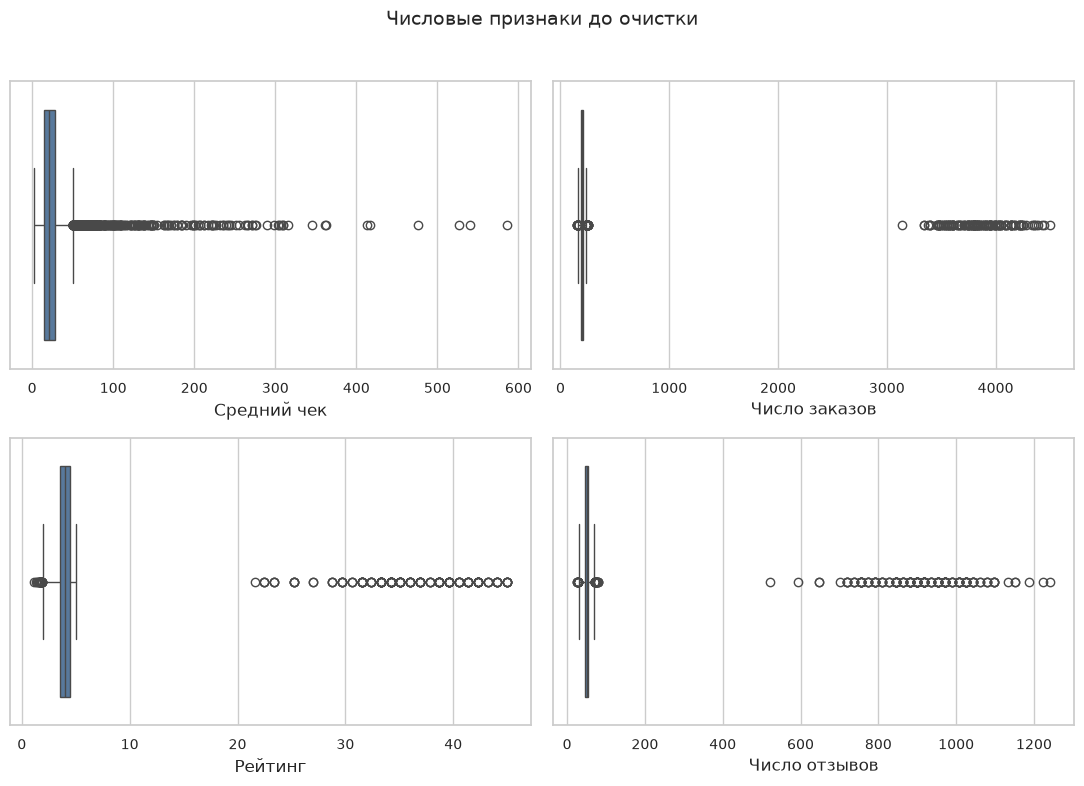

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (column, label) in zip(axes.ravel(), VARIABLES):
    sns.boxplot(data=df, x=column, ax=ax, color=SINGLE_COLOR)
    ax.set_xlabel(label)
    ax.set_ylabel("")
fig.suptitle("Числовые признаки до очистки")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_mpl(fig, "01-before-boxplots.png")
plt.show()
plt.close(fig)


Рисунок 1 – Числовые признаки до очистки

У заказов, рейтинга и отзывов виден оторванный правый кластер. У среднего чека кластера нет, есть длинный правый хвост. Этот рисунок обосновывает правила подготовки и в отчёт входит в решение задачи о подготовке данных.


Чтобы проверить, что правила убрали именно кластеры, повторяем те же четыре ящика на очищенной таблице. Точки за усами на этом рисунке — хвост уже допустимого распределения, а не значения в тысячи заказов.


media/02-after-boxplots.png


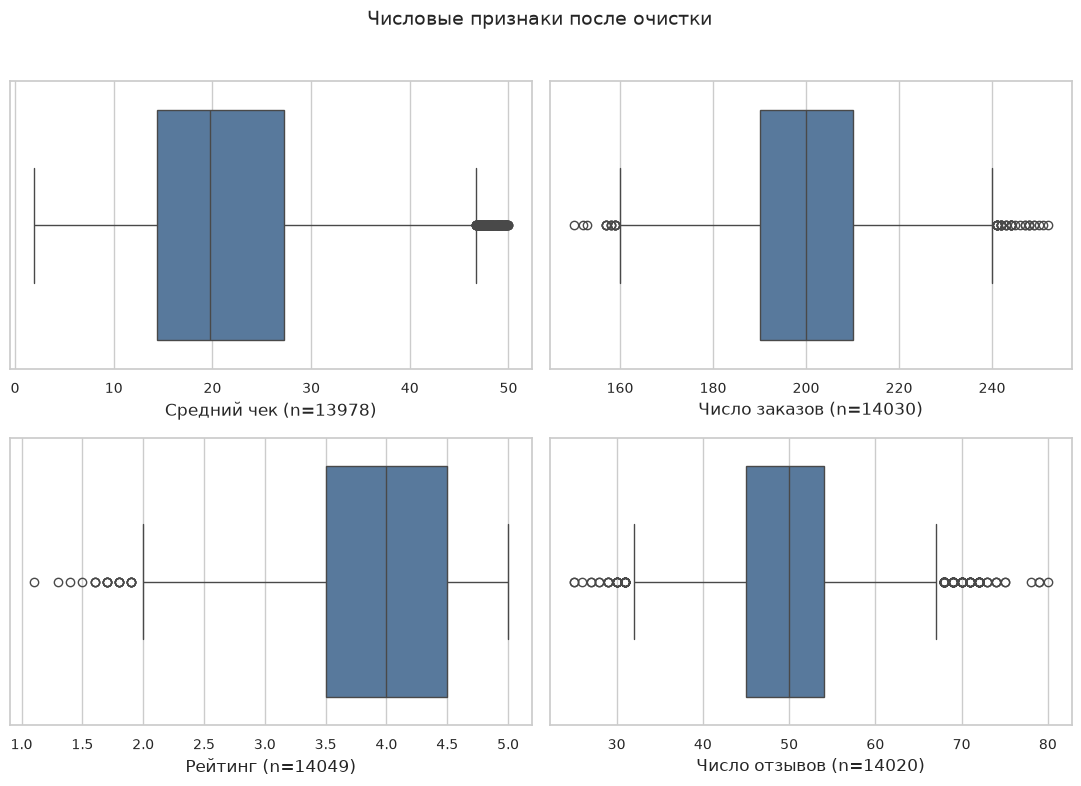

Непустых значений по столбцам: было → стало
  Средний чек: 15011 → 13978
  Число заказов: 15002 → 14030
  Рейтинг: 15014 → 14049
  Число отзывов: 14990 → 14020


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (column, label) in zip(axes.ravel(), VARIABLES):
    sns.boxplot(data=df_clean, x=column, ax=ax, color=SINGLE_COLOR)
    filled = int(df_clean[column].notna().sum())
    ax.set_xlabel(f"{label} (n={filled})")
    ax.set_ylabel("")
fig.suptitle("Числовые признаки после очистки")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_mpl(fig, "02-after-boxplots.png")
plt.show()
plt.close(fig)

print("Непустых значений по столбцам: было → стало")
for column, label in VARIABLES:
    print(f"  {label}: {int(df[column].notna().sum())} → {int(df_clean[column].notna().sum())}")


Рисунок 2 – Числовые признаки после очистки

Кластеры заказов, рейтинга и отзывов ушли. Дальше все содержательные рисунки строятся по одной рабочей выборке: кухня и четыре числа заполнены, выбросы уже исключены. Так у рисунков 3–10 одинаковый состав строк, и их можно сравнивать между собой.


In [6]:
needed = ["Avg_Check", "Orders", "Rating", "Reviews", "Кухня"]
base = df_clean.dropna(subset=needed).copy()
for column in ["Avg_Check", "Orders", "Rating", "Reviews"]:
    base[column] = base[column].astype(float)
base["Кухня"] = pd.Categorical(base["Кухня"], categories=CUISINE_ORDER, ordered=True)
if base.empty:
    raise RuntimeError("Рабочая выборка пуста: проверьте правила очистки")

base_ru = base.rename(columns=RU)
# Оборот в исходном CSV отсутствует. Это произведение двух столбцов для долей по кухням.
base_ru["Оборот"] = base_ru["Средний чек"] * base_ru["Число заказов"]
base_ru["Ресторан"] = base_ru["Restaurant"].astype("string").fillna("без названия")

print(f"Рабочая выборка для рисунков 3–10: {len(base_ru)} строк")
print("Строк по кухням:")
display(base_ru["Кухня"].value_counts().sort_index())
display(base_ru[list(RU.values())].describe().T.round(3))


Рабочая выборка для рисунков 3–10: 9097 строк
Строк по кухням:


Кухня
Индийская       1538
Итальянская     1448
Китайская       1464
Мексиканская    1535
Французская     1521
Японская        1591
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
Средний чек,9097.0,21.572,9.561,1.89,14.46,19.81,27.3,49.96
Число заказов,9097.0,200.179,14.357,150.00,191.00,200.00,210.0,251.00
Рейтинг,9097.0,3.967,0.665,1.30,3.50,4.00,4.5,5.00
Число отзывов,9097.0,49.871,7.031,25.00,45.00,50.00,54.0,79.00


## 4. Визуализация в Seaborn

Для того чтобы проверить гипотезу статическими графиками, строим распределение рейтинга, сравнение кухонь, связь чека и рейтинга, матрицу корреляций и парные диаграммы. Библиотека — Seaborn, как высокоуровневая обёртка над Matplotlib: так устроен соответствующий раздел методички.

Ящик на рисунке 4 читается по правилу из методички: коробка — интерквартильный размах от 25-го до 75-го перцентиля, черта внутри — медиана, усы — диапазон до 1,5 интерквартильного размаха, точки — значения за усами.


Чтобы увидеть форму рейтинга на шкале от 1 до 5, строим гистограмму с шагом 0,1 балла и оценкой плотности. Это замена `distplot` из методички.


media/03-rating-hist.png


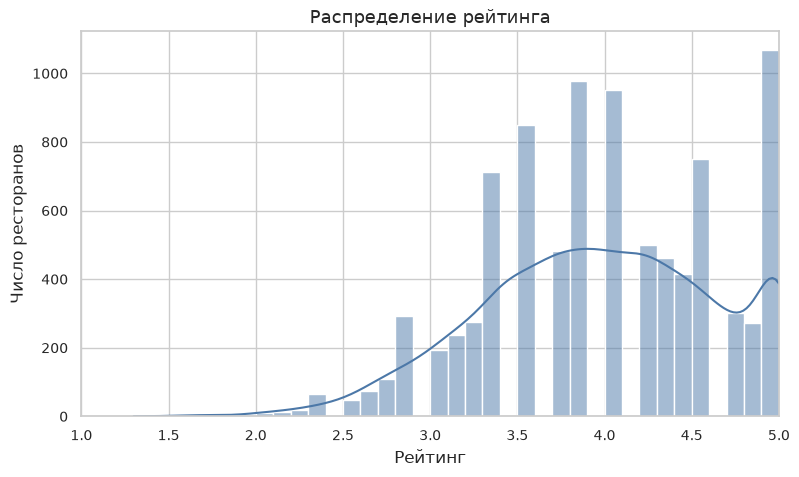

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=base_ru,
    x="Рейтинг",
    binwidth=0.1,
    kde=True,
    color=SINGLE_COLOR,
    ax=ax,
)
ax.set_xlim(1, 5)
ax.set_xlabel("Рейтинг")
ax.set_ylabel("Число ресторанов")
ax.set_title("Распределение рейтинга")
save_mpl(fig, "03-rating-hist.png")
plt.show()
plt.close(fig)


Рисунок 3 – Распределение рейтинга

Рисунок отвечает на вопрос, как устроена шкала оценок после очистки. Для отчёта он входит в решение задачи по Seaborn и показывает, вокруг какого балла собраны заведения, прежде чем сравнивать кухни.


Чтобы проверить, отличается ли рейтинг кухонь, строим горизонтальные ящики. Горизонтальное расположение такое же, как у сравнения платформ в методичке: подписи кухонь читаются целиком.


media/04-rating-by-cuisine.png


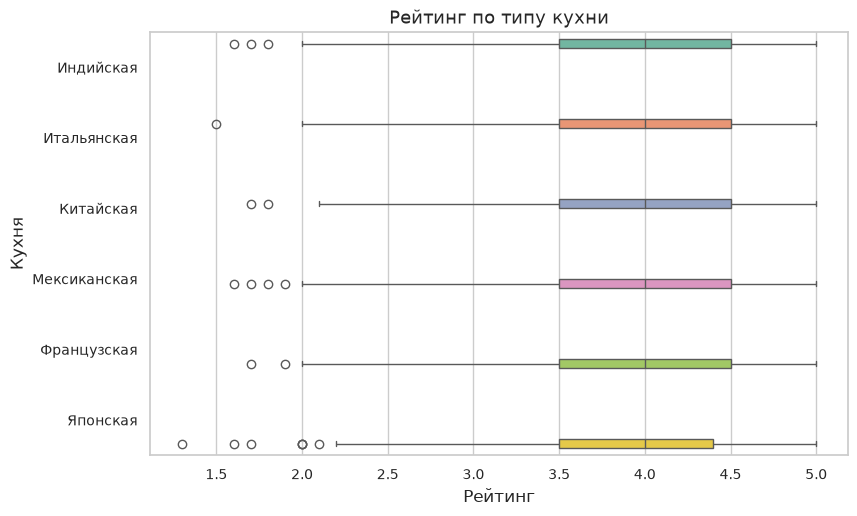

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(
    data=base_ru,
    y="Кухня",
    x="Рейтинг",
    order=CUISINE_ORDER,
    hue="Кухня",
    hue_order=CUISINE_ORDER,
    palette=PALETTE,
    legend=False,
    ax=ax,
)
ax.set_xlabel("Рейтинг")
ax.set_ylabel("Кухня")
ax.set_title("Рейтинг по типу кухни")
save_mpl(fig, "04-rating-by-cuisine.png")
plt.show()
plt.close(fig)


Рисунок 4 – Рейтинг по типу кухни

Рисунок отвечает на вопрос, есть ли кухня с заметно более высоким рейтингом. Если медианы и коробки совпадают, часть гипотезы о выборе кухни по рейтингу не видна на графике. Рисунок входит в решение задачи по Seaborn.


Чтобы проверить связь среднего чека и рейтинга, строим `jointplot`: рассеяние двух признаков, гистограммы по краям и прямую регрессии без доверительной полосы. В методичке у `jointplot` по умолчанию только точки и гистограммы; прямая добавлена, потому что гипотеза говорит именно о наклоне.


media/05-check-rating-joint.png


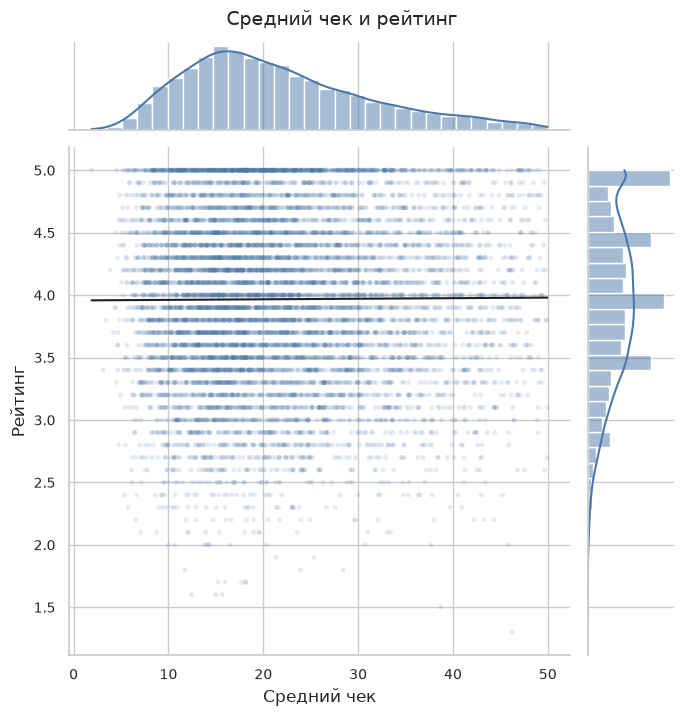

In [9]:
joint = sns.jointplot(
    data=base_ru,
    x="Средний чек",
    y="Рейтинг",
    kind="reg",
    height=7,
    color=SINGLE_COLOR,
    ci=None,
    scatter_kws={"alpha": 0.15, "s": 12, "edgecolor": "none"},
    line_kws={"color": "#1f1f1f", "linewidth": 1.5},
    marginal_kws={"bins": 30},
)
joint.set_axis_labels("Средний чек", "Рейтинг")
joint.figure.suptitle("Средний чек и рейтинг", y=1.02)
save_mpl(joint.figure, "05-check-rating-joint.png")
plt.show()
plt.close(joint.figure)


Рисунок 5 – Средний чек и рейтинг

Рисунок отвечает на вопрос, растёт ли рейтинг вместе со средним чеком. Горизонтальная прямая и круглое облако означают, что связи, на которую опирается гипотеза, на рабочей выборке нет. Рисунок входит в решение задачи по Seaborn.


Чтобы увидеть все четыре числовые связи сразу, считаем корреляции Пирсона и рисуем тепловую карту. Шкала зафиксирована от −1 до 1, как у коэффициента, а не поджата под фактические значения: иначе почти нулевая матрица выглядела бы контрастной. Формат подписей `.2f`, а не `.1f` из примера методички, потому что при значениях около нуля один знак после запятой скрыл бы сам результат.


Корреляции Пирсона:


,Средний чек,Число заказов,Рейтинг,Число отзывов
Средний чек,1.000,-0.003,0.007,0.006
Число заказов,-0.003,1.000,0.010,-0.002
Рейтинг,0.007,0.010,1.000,0.001
Число отзывов,0.006,-0.002,0.001,1.000


Корреляции Спирмена:


,Средний чек,Число заказов,Рейтинг,Число отзывов
Средний чек,1.000,-0.003,0.006,0.004
Число заказов,-0.003,1.000,0.008,-0.002
Рейтинг,0.006,0.008,1.000,0.005
Число отзывов,0.004,-0.002,0.005,1.000


media/06-correlation-heatmap.png


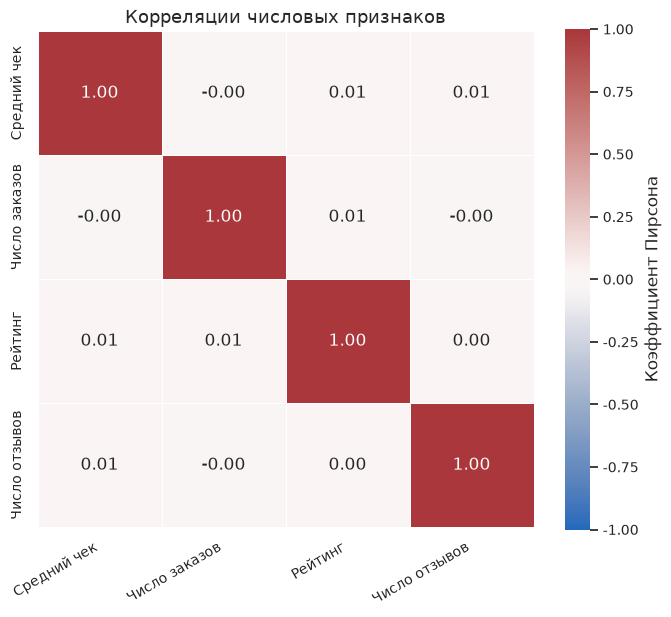

In [10]:
numeric_labels = list(RU.values())
corr_pearson = base_ru[numeric_labels].corr(method="pearson")
corr_spearman = base_ru[numeric_labels].corr(method="spearman")
print("Корреляции Пирсона:")
display(corr_pearson.round(3))
print("Корреляции Спирмена:")
display(corr_spearman.round(3))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Коэффициент Пирсона"},
    ax=ax,
)
for label in ax.get_xticklabels():
    label.set_rotation(30)
    label.set_ha("right")
ax.set_title("Корреляции числовых признаков")
save_mpl(fig, "06-correlation-heatmap.png")
plt.show()
plt.close(fig)


Рисунок 6 – Корреляции числовых признаков

Рисунок отвечает на вопрос, есть ли среди чека, заказов, рейтинга и отзывов пара с заметной связью. Бледная карта при шкале от −1 до 1 — содержательный результат. Рисунок входит в решение задачи по Seaborn. Во второй части методички такая карта используется, чтобы убрать признаки, которые повторяют друг друга; здесь она проверяет гипотезу о связи рейтинга с чеком, заказами и отзывами.


Чтобы проверить, не разделяются ли кухни хотя бы в какой-то проекции, строим матрицу парных диаграмм. На диагонали — гистограммы признака, вне диагонали — рассеяние пар. Цвет точки — кухня. Это первый «сложный» график Seaborn в методичке, перенесённый на четыре числовых столбца ресторанов.


media/07-pairplot.png


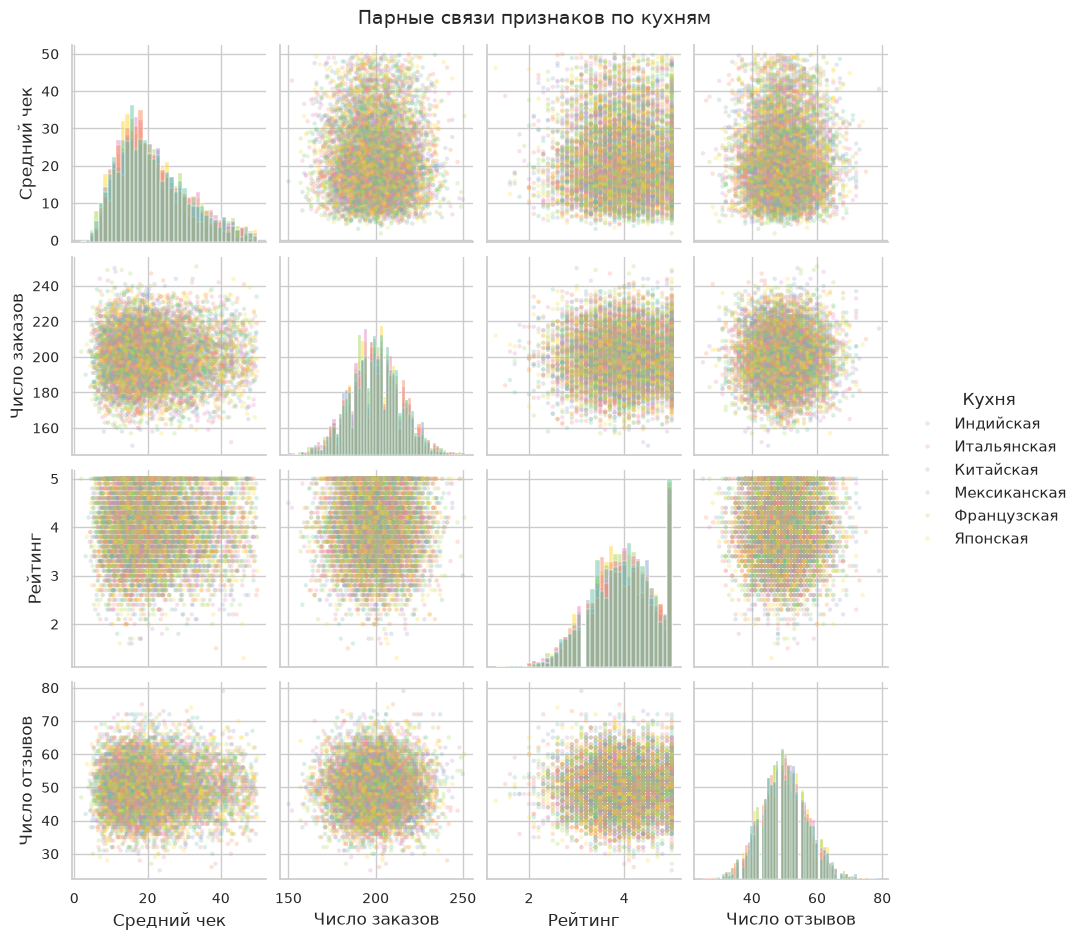

In [11]:
pair = sns.pairplot(
    base_ru,
    vars=numeric_labels,
    hue="Кухня",
    hue_order=CUISINE_ORDER,
    palette=PALETTE,
    diag_kind="hist",
    plot_kws={"alpha": 0.25, "s": 10, "edgecolor": "none"},
    height=2.3,
)
pair.figure.suptitle("Парные связи признаков по кухням", y=1.02)
save_mpl(pair.figure, "07-pairplot.png")
plt.show()
plt.close(pair.figure)


Рисунок 7 – Парные связи признаков по кухням

Рисунок отвечает на вопрос, образует ли какая-нибудь кухня отдельное облако по чеку, заказам, рейтингу или отзывам. Если цвета перемешаны, кухни на этих признаках не разделяются. Рисунок входит в решение задачи по Seaborn.


## 5. Визуализация в Plotly

Для того чтобы закрыть пятую задачу и проверить те же вопросы интерактивно, строим три рисунка Plotly: групповые столбцы долей, ящик среднего чека по кухням и рассеяние чека против рейтинга. В методичке фигура собирается из трасс `go.Bar`, `go.Box` и `go.Scatter`, затем задаётся `layout`. Здесь тот же порядок. Ссылка на сайт plot.ly не добавляется: в текущем API её нет, и методичка рекомендует её скрывать.

Рядом с каждым PNG лежит HTML. В HTML можно навести курсор на точку и, на рассеянии, отключить кухню в легенде.


Чтобы проверить, доминирует ли какая-нибудь кухня по числу заведений или по обороту, считаем две доли на одной оси. Так переносится столбчатое сравнение «число игр и выручка по платформам»: разные абсолютные шкалы не рисуются на одной оси, сравниваются проценты. Оборот — произведение среднего чека и числа заказов.


In [12]:
grouped = base_ru.groupby("Кухня", observed=True)
counts = grouped.size()
turnover_sums = grouped["Оборот"].sum()
share_places = counts / counts.sum() * 100
share_turnover = turnover_sums / turnover_sums.sum() * 100

share_table = pd.DataFrame({
    "Заведений": counts.astype(int),
    "Доля заведений, %": share_places,
    "Оборот": turnover_sums,
    "Доля оборота, %": share_turnover,
})
display(share_table.round(2))
print(
    "Размах долей заведений, п.п.:",
    round(float(share_places.max() - share_places.min()), 2),
)
print(
    "Размах долей оборота, п.п.:",
    round(float(share_turnover.max() - share_turnover.min()), 2),
)

fig = go.Figure()
fig.add_trace(go.Bar(
    x=list(share_places.index.astype(str)),
    y=share_places.to_numpy(),
    name="Доля заведений",
    marker_color="#4C78A8",
    text=[f"{value:.1f}" for value in share_places.to_numpy()],
    textposition="outside",
    customdata=counts.to_numpy(),
    hovertemplate="%{x}<br>Доля заведений: %{y:.1f}%<br>Заведений: %{customdata:.0f}<extra></extra>",
))
fig.add_trace(go.Bar(
    x=list(share_turnover.index.astype(str)),
    y=share_turnover.to_numpy(),
    name="Доля оборота",
    marker_color="#F58518",
    text=[f"{value:.1f}" for value in share_turnover.to_numpy()],
    textposition="outside",
    customdata=turnover_sums.to_numpy(),
    hovertemplate="%{x}<br>Доля оборота: %{y:.1f}%<br>Сумма оборота: %{customdata:.0f}<extra></extra>",
))
apply_layout(fig, "Доли заведений и оборота по кухням", "Кухня", "Доля, %")
ymax = float(max(share_places.max(), share_turnover.max()))
fig.update_layout(barmode="group")
fig.update_yaxes(range=[0, ymax * 1.28])
fig.update_xaxes(categoryorder="array", categoryarray=CUISINE_ORDER, tickangle=-20)
save_plotly(fig, "08-cuisine-shares")


,Заведений,"Доля заведений, %",Оборот,"Доля оборота, %"
Кухня,,,,
Индийская,1538,16.91,6602431.18,16.81
Итальянская,1448,15.92,6188965.19,15.76
Китайская,1464,16.09,6327852.57,16.11
Мексиканская,1535,16.87,6681428.99,17.01
Французская,1521,16.72,6638092.60,16.90
Японская,1591,17.49,6840445.24,17.41


Размах долей заведений, п.п.: 1.57
Размах долей оборота, п.п.: 1.66


media/08-cuisine-shares.png
media/08-cuisine-shares.html


Рисунок 8 – Доли заведений и оборота по кухням

Рисунок отвечает на вопрос, есть ли кухня, которая занимает заметно большую долю сети или оборота. Равные столбцы около одной шестой означают, что приоритетной кухни по объёму нет. Рисунок входит в решение задачи по Plotly.


Чтобы проверить, отличается ли средний чек кухонь, строим ящики Plotly. Это перенос ящика «оценка критиков по жанрам» на единственную категорию файла и на признак чека. Рейтинг по кухням уже показан в Seaborn, здесь другой признак, чтобы две библиотеки не дублировали один и тот же график.


In [13]:
fig = go.Figure()
for cuisine in CUISINE_ORDER:
    part = base_ru.loc[base_ru["Кухня"] == cuisine, "Средний чек"]
    fig.add_trace(go.Box(
        y=part,
        name=cuisine,
        marker_color=PALETTE[cuisine],
        line_color=PALETTE[cuisine],
        boxpoints="outliers",
        showlegend=False,
    ))
apply_layout(fig, "Средний чек по типу кухни", "Кухня", "Средний чек")
fig.update_xaxes(categoryorder="array", categoryarray=CUISINE_ORDER, tickangle=-20)
save_plotly(fig, "09-check-by-cuisine")


media/09-check-by-cuisine.png
media/09-check-by-cuisine.html


Рисунок 9 – Средний чек по типу кухни

Рисунок отвечает на вопрос, есть ли кухня с заметно другим средним чеком. Совпадающие коробки и медианы означают, что выбирать кухню по чеку нельзя. Рисунок входит в решение задачи по Plotly.


Чтобы интерактивно проверить ту же связь, что на рисунке 5, и увидеть, не прячется ли наклон внутри одной кухни, строим рассеяние Plotly. Каждая кухня — отдельная трасса: её можно отключить в легенде HTML-файла. В подсказке точки — имя заведения, заказы и отзывы.


In [14]:
fig = go.Figure()
for cuisine in CUISINE_ORDER:
    part = base_ru.loc[base_ru["Кухня"] == cuisine]
    fig.add_trace(go.Scatter(
        x=part["Средний чек"],
        y=part["Рейтинг"],
        mode="markers",
        name=cuisine,
        marker=dict(color=PALETTE[cuisine], size=6, opacity=0.45),
        customdata=np.column_stack([
            part["Число заказов"].to_numpy(),
            part["Число отзывов"].to_numpy(),
            part["Ресторан"].astype(str).to_numpy(),
        ]),
        hovertemplate=(
            "%{customdata[2]}<br>"
            "Кухня: %{fullData.name}<br>"
            "Средний чек: %{x:.2f}<br>"
            "Рейтинг: %{y:.1f}<br>"
            "Заказы: %{customdata[0]:.0f}<br>"
            "Отзывы: %{customdata[1]:.0f}"
            "<extra></extra>"
        ),
    ))
apply_layout(
    fig,
    "Средний чек и рейтинг по кухням",
    "Средний чек",
    "Рейтинг",
    legend_title="Кухня",
    height=620,
)
save_plotly(fig, "10-check-rating-scatter")


media/10-check-rating-scatter.png
media/10-check-rating-scatter.html


Рисунок 10 – Средний чек и рейтинг по кухням

Рисунок отвечает на вопрос, есть ли наклон «чем выше чек, тем выше рейтинг» хотя бы у одной кухни. Перемешанное облако без наклона означает, что связь не появляется и после раскраски по кухне. Рисунок входит в решение задачи по Plotly.


## Выводы

В ходе выполнения работы мы изучили срез ресторанов шести кухонь и убедились, что времени в файле нет, поэтому динамический ряд из примера с играми не строится. Мы подготовили данные: пропуски оставили пустыми и убирали только в столбцах конкретного рисунка, а строки с недопустимыми числами исключили по разрывам распределения и по верхнему усу Тьюки для среднего чека. Мы построили статические графики в Seaborn и интерактивные графики в Plotly и сохранили их в каталог `media`.

Итог проверки гипотезы печатает следующая ячейка. Текст собран из корреляций и медиан рабочей выборки, а не из заранее подставленных чисел.


In [15]:
medians = base_ru.groupby("Кухня", observed=True)[numeric_labels].median()
medians.insert(0, "Заведений", base_ru.groupby("Кухня", observed=True).size())
print("Медианы рабочей выборки:")
display(medians.round(3))

pearson = max_abs_offdiag(corr_pearson)
spearman = max_abs_offdiag(corr_spearman)
span_rating = float(medians["Рейтинг"].max() - medians["Рейтинг"].min())
span_orders = float(medians["Число заказов"].max() - medians["Число заказов"].min())
span_check = float(medians["Средний чек"].max() - medians["Средний чек"].min())

raw_complete = df[["Avg_Check", "Orders", "Rating", "Reviews"]].dropna()
raw_corr = raw_complete.rename(columns=RU).corr(method="pearson")
raw_pearson = max_abs_offdiag(raw_corr)
print("Корреляции Пирсона на всех полных строках, без отсечения выбросов:")
display(raw_corr.round(3))

hits = []
if max(pearson, spearman) >= CORR_LIMIT:
    hits.append("корреляция числовых признаков")
if span_rating >= RATING_MEDIAN_SPAN:
    hits.append("медианный рейтинг кухонь")
if span_orders >= ORDERS_MEDIAN_SPAN:
    hits.append("медианное число заказов")
if span_check >= CHECK_MEDIAN_SPAN:
    hits.append("медианный средний чек")

print()
print(f"Рабочая выборка для рисунков 3–10: {len(base_ru)} строк.")
print(f"Максимальный модуль корреляции Пирсона вне диагонали: {pearson:.3f}.")
print(f"Максимальный модуль корреляции Спирмена вне диагонали: {spearman:.3f}.")
print(f"Размах медиан рейтинга между кухнями: {span_rating:.3f} балла.")
print(f"Размах медиан числа заказов: {span_orders:.2f}.")
print(f"Размах медиан среднего чека: {span_check:.2f}.")
print(
    "Максимальный модуль корреляции Пирсона на полных строках без отсечения выбросов: "
    f"{raw_pearson:.3f}."
)
if hits:
    print(
        "Полученные результаты показали, что заранее заданные пороги достигнуты: "
        + ", ".join(hits)
        + ". В этих пунктах гипотеза получает поддержку графиков."
    )
else:
    print(
        "Полученные результаты показали, что ни один заранее заданный порог не достигнут. "
        "Гипотеза не подтверждается: по этим данным нельзя выбрать кухню для расширения "
        "и нельзя утверждать, что более высокий рейтинг сопровождается большим числом заказов, "
        "отзывов или более высоким средним чеком."
    )


Медианы рабочей выборки:


,Заведений,Средний чек,Число заказов,Рейтинг,Число отзывов
Кухня,,,,,
Индийская,1538,19.780,200.0,4.0,50.0
Итальянская,1448,19.515,200.0,4.0,50.0
Китайская,1464,20.055,200.0,4.0,49.0
Мексиканская,1535,19.800,200.0,4.0,50.0
Французская,1521,19.980,200.0,4.0,50.0
Японская,1591,19.830,199.0,4.0,50.0


Корреляции Пирсона на всех полных строках, без отсечения выбросов:


,Средний чек,Число заказов,Рейтинг,Число отзывов
Средний чек,1.000,-0.006,-0.001,-0.007
Число заказов,-0.006,1.000,0.014,-0.010
Рейтинг,-0.001,0.014,1.000,0.026
Число отзывов,-0.007,-0.010,0.026,1.000



Рабочая выборка для рисунков 3–10: 9097 строк.
Максимальный модуль корреляции Пирсона вне диагонали: 0.010.
Максимальный модуль корреляции Спирмена вне диагонали: 0.008.
Размах медиан рейтинга между кухнями: 0.000 балла.
Размах медиан числа заказов: 1.00.
Размах медиан среднего чека: 0.54.
Максимальный модуль корреляции Пирсона на полных строках без отсечения выбросов: 0.026.
Полученные результаты показали, что ни один заранее заданный порог не достигнут. Гипотеза не подтверждается: по этим данным нельзя выбрать кухню для расширения и нельзя утверждать, что более высокий рейтинг сопровождается большим числом заказов, отзывов или более высоким средним чеком.


## Проверка сохранённых файлов

Ячейка ниже проверяет, что каждый рисунок записан на диск и не пустой. Это страховка прогона, а не ещё один график.


In [16]:
expected_files = [
    "01-before-boxplots.png",
    "02-after-boxplots.png",
    "03-rating-hist.png",
    "04-rating-by-cuisine.png",
    "05-check-rating-joint.png",
    "06-correlation-heatmap.png",
    "07-pairplot.png",
    "08-cuisine-shares.png",
    "08-cuisine-shares.html",
    "09-check-by-cuisine.png",
    "09-check-by-cuisine.html",
    "10-check-rating-scatter.png",
    "10-check-rating-scatter.html",
]
problems = []
for name in expected_files:
    path = MEDIA_DIR / name
    if not path.is_file():
        problems.append(f"нет файла: {name}")
        continue
    size = path.stat().st_size
    minimum = 10_000 if path.suffix == ".png" else 50_000
    header = path.read_bytes()[:8]
    if size < minimum:
        problems.append(f"слишком малый файл: {name} ({size} байт)")
    if path.suffix == ".png" and header != b"\x89PNG\r\n\x1a\n":
        problems.append(f"это не PNG: {name}")
    print(f"{path}  {size}")
if problems:
    raise RuntimeError("; ".join(problems))
print(f"Файлов рисунков: {len(expected_files)}")


media/01-before-boxplots.png  63932
media/02-after-boxplots.png  67814
media/03-rating-hist.png  44548
media/04-rating-by-cuisine.png  42363
media/05-check-rating-joint.png  281267
media/06-correlation-heatmap.png  70909


media/07-pairplot.png  1252488
media/08-cuisine-shares.png  113090
media/08-cuisine-shares.html  4826230
media/09-check-by-cuisine.png  101013


media/09-check-by-cuisine.html  4926273
media/10-check-rating-scatter.png  897997
media/10-check-rating-scatter.html  5311408
Файлов рисунков: 13


## Источники приёмов

Приёмы графиков взяты из методических указаний «Лабораторная работа 1. Визуализация данных средствами Python»: `pairplot`, гистограмма с плотностью, `jointplot`, ящик, тепловая карта, столбцы и ящики Plotly, чтение правил ящика (квартили, усы, точки). Вторая часть тех же указаний даёт тепловую карту корреляций. Данные ресторанов — отдельный CSV, не выборка видеоигр и не таблица оттока из указаний.

Рекомендованные указаниями страницы, к которым относятся использованные типы графиков:

1. Seaborn — https://blog.skillfactory.ru/glossary/seaborn/
2. Диаграмма размаха — https://datavizcatalogue.com/RU/metody/diagramma_razmaha.html
3. Тепловая карта — https://datavizcatalogue.com/RU/metody/teplovaja_karta.html
